In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR, TLS224_APPLN_CPC,
)

patstat = PatstatClient(env="TEST")
db = patstat.orm()


In [ ]:
SECTOR_NAME = "Quantum computing"

SECTOR_CPC_CODES = (
    "G06N10/",       # quantum computing
    "H04L9/0852",    # quantum cryptography
    "H04L9/0855",
    "H04L9/0858",
    "H04B10/70",     # quantum communication
)

SECTOR_KEYWORDS = (
    "quantum comput", "qubit", "quantum processor", "quantum algorithm",
    "quantum circuit", "quantum gate", "quantum annealing", "quantum annealer",
    "quantum error correction",
)

YEAR_MIN, YEAR_MAX = 2000, 2025
LAST_COMPLETE_YEAR = 2022   # the last ~3 years are incomplete in PATSTAT (explained later)


In [3]:
def code_filter(column, codes):
    clean = func.replace(column, " ", "")
    return or_(*[clean.like(f"{c}%") for c in codes])


def keyword_filter(terms):
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*[title.like(f"%{t}%") for t in terms], *[abstract.like(f"%{t}%") for t in terms])


family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")

q_cpc = (
    db.query(family_id)
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(code_filter(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_CODES))
)
q_kw = (
    db.query(family_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(keyword_filter(SECTOR_KEYWORDS))
)

sector_families = set(patstat.df(q_cpc.union(q_kw))["docdb_family_id"])
print(len(sector_families), "quantum families")


30 quantum families


cell 4: Get all tthe applications of the families

In [4]:
df = patstat.df(
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
    )
    .filter(
        TLS201_APPLN.docdb_family_id.in_(list(sector_families)),
        TLS201_APPLN.ipr_type == "PI",
    )
)
print(len(df), "applications in", df["docdb_family_id"].nunique(), "families")
df.head()


42 applications in 30 families


,appln_id,docdb_family_id,appln_auth,appln_filing_year,earliest_filing_year,granted,docdb_family_size
0,52379660,31495908,US,2003,2002,N,3
1,49529356,35427565,US,2005,2004,N,2
2,406811995,45723016,US,2010,2010,Y,5
3,440367647,53126338,CN,2014,2014,Y,1
4,486002014,60242617,US,2017,2016,Y,6


5

In [5]:
family_year = df.groupby("docdb_family_id")["earliest_filing_year"].min()

per_year = pd.DataFrame({
    "families": family_year.value_counts(),
    "applications": df["appln_filing_year"].value_counts(),
}).fillna(0).astype(int).sort_index()

per_year = per_year.reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0)
per_year


,families,applications
2000,0,0
2001,0,0
2002,1,0
2003,0,1
2004,1,0
2005,0,1
2006,0,0
2007,0,0
2008,0,0
2009,0,0


6

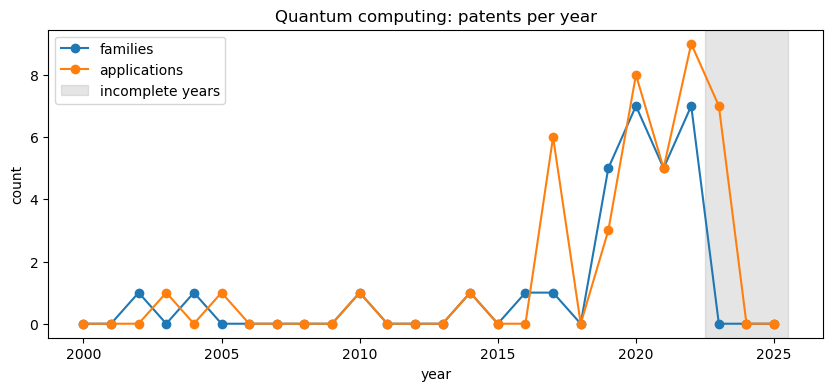

In [6]:
ax = per_year.plot(marker="o", figsize=(10, 4), title=f"{SECTOR_NAME}: patents per year")
ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.2, label="incomplete years")
ax.set(xlabel="year", ylabel="count")
ax.legend()
plt.show()


7

In [7]:
rows_fam = patstat.sql_query("""
    SELECT year, COUNT(*) AS families
    FROM (
        SELECT docdb_family_id, MIN(earliest_filing_year) AS year
        FROM tls201_appln
        WHERE ipr_type = 'PI'
        GROUP BY docdb_family_id
    )
    GROUP BY year
""", use_legacy_sql=False)

rows_app = patstat.sql_query("""
    SELECT appln_filing_year AS year, COUNT(*) AS applications
    FROM tls201_appln
    WHERE ipr_type = 'PI'
    GROUP BY appln_filing_year
""", use_legacy_sql=False)

all_per_year = (
    pd.DataFrame(rows_fam).set_index("year")
    .join(pd.DataFrame(rows_app).set_index("year"), how="outer")
    .reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0)
    .fillna(0)
)
all_per_year.tail()


,families,applications
year,,
2021,16405.0,21612
2022,10902.0,14162
2023,2756.0,3911
2024,0.0,3
2025,0.0,0


8

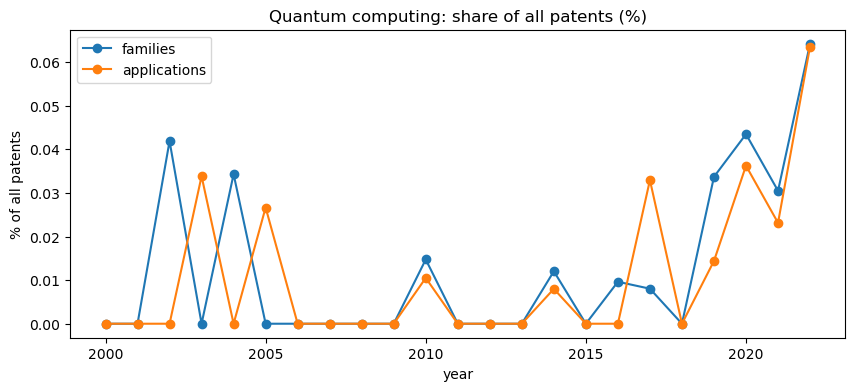

In [8]:
share = per_year / all_per_year * 100

ax = share.loc[:LAST_COMPLETE_YEAR].plot(marker="o", figsize=(10, 4),
                                          title=f"{SECTOR_NAME}: share of all patents (%)")
ax.set(xlabel="year", ylabel="% of all patents")
plt.show()


9

In [9]:
early = range(2013, 2018)                       # 2013–2017
late = range(2018, LAST_COMPLETE_YEAR + 1)      # 2018–2022

growth = pd.DataFrame({
    "2013-2017": [per_year.loc[early, "families"].sum(), all_per_year.loc[early, "families"].sum()],
    "2018-2022": [per_year.loc[late, "families"].sum(), all_per_year.loc[late, "families"].sum()],
}, index=[SECTOR_NAME, "all patents"])
growth["growth (%)"] = (growth["2018-2022"] / growth["2013-2017"] - 1) * 100
growth


,2013-2017,2018-2022,growth (%)
Quantum computing,3.0,24.0,700.000000
all patents,48261.0,72586.0,50.403017


10

In [10]:
df_cpc = patstat.df(
    db.query(
        TLS224_APPLN_CPC.appln_id,
        func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4).label("subclass"),
    )
    .filter(TLS224_APPLN_CPC.appln_id.in_(df["appln_id"].tolist()))
)

fam_cpc = (
    df_cpc.merge(df[["appln_id", "docdb_family_id"]], on="appln_id")
    [["docdb_family_id", "subclass"]]
    .drop_duplicates()
)
fam_cpc["weight"] = 1 / fam_cpc.groupby("docdb_family_id")["subclass"].transform("count")

mix = fam_cpc.groupby("subclass")["weight"].sum().sort_values(ascending=False)
mix_pct = (mix / mix.sum() * 100).round(1)

print(fam_cpc["docdb_family_id"].nunique(), "families have CPC codes")
mix_pct.head(10)


30 families have CPC codes


subclass
G06N    45.1
G06F    13.6
H04L    13.5
G06Q     5.1
Y02T     3.3
B82Y     2.8
Y02E     2.6
H02J     2.4
Y04S     1.9
G06E     1.7
Name: weight, dtype: float64

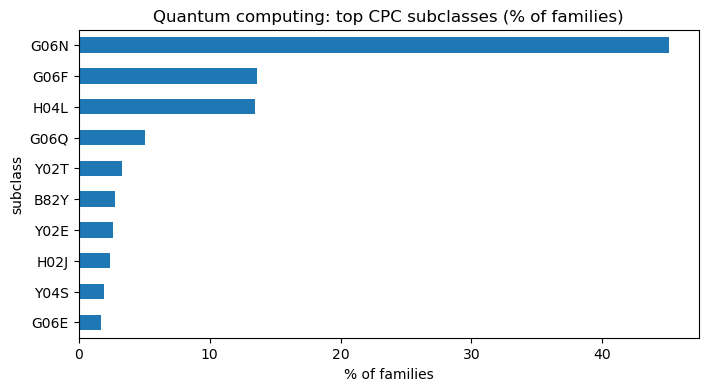

In [11]:
mix_pct.head(10).sort_values().plot.barh(
    figsize=(8, 4), title=f"{SECTOR_NAME}: top CPC subclasses (% of families)"
)
plt.xlabel("% of families")
plt.show()


12: offices

In [12]:
IP5 = ["EP", "US", "CN", "JP", "KR"]   # the 5 biggest patent offices

office = df["appln_auth"].where(df["appln_auth"].isin(IP5 + ["WO"]), "Other")

offices = pd.DataFrame({
    "applications (%)": (office.value_counts(normalize=True) * 100).round(1),
    "families with an application there": df.assign(office=office).groupby("office")["docdb_family_id"].nunique(),
}).sort_values("applications (%)", ascending=False)
offices


,applications (%),families with an application there
US,38.1,14
Other,23.8,7
CN,16.7,7
WO,14.3,5
EP,2.4,1
JP,2.4,1
KR,2.4,1


13: contries

In [13]:
from epo.tipdata.patstat.database.models import TLS206_PERSON, TLS207_PERS_APPLN

df_pers = patstat.df(
    db.query(
        TLS207_PERS_APPLN.appln_id,
        TLS207_PERS_APPLN.person_id,
        TLS207_PERS_APPLN.applt_seq_nr,
        TLS207_PERS_APPLN.invt_seq_nr,
        func.trim(TLS206_PERSON.person_ctry_code).label("ctry"),
    )
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(TLS207_PERS_APPLN.appln_id.in_(df["appln_id"].tolist()))
)
df_pers = df_pers.merge(df[["appln_id", "docdb_family_id"]], on="appln_id")
df_pers = df_pers[df_pers["ctry"].fillna("") != ""]      # drop unknown countries


def country_shares(people):
    """Split each family equally among its persons; return % per country."""
    p = people.drop_duplicates(["docdb_family_id", "person_id"]).copy()
    p["weight"] = 1 / p.groupby("docdb_family_id")["person_id"].transform("count")
    s = p.groupby("ctry")["weight"].sum()
    return (s / s.sum() * 100).round(1)


countries = pd.DataFrame({
    "applicants (%)": country_shares(df_pers[df_pers["applt_seq_nr"] > 0]),
    "inventors (%)": country_shares(df_pers[df_pers["invt_seq_nr"] > 0]),
}).fillna(0).sort_values("applicants (%)", ascending=False)
countries.head(10)


,applicants (%),inventors (%)
ctry,,
US,39.1,40.9
DE,34.8,31.8
JP,10.9,11.1
CA,4.3,4.5
KR,4.3,4.5
CN,4.3,4.5
IT,2.2,2.0
RU,0.0,0.5
